In [1]:
!pip -q install sentence-transformers scikit-learn pandas numpy matplotlib


In [2]:
import json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
from sklearn.cluster import Birch
from sklearn.feature_extraction.text import TfidfVectorizer


In [3]:
from google.colab import files
uploaded = files.upload()
JSON_FILE = list(uploaded.keys())[0]
print("Using:", JSON_FILE)


Saving reduced_icecat_data_train_transformed.json to reduced_icecat_data_train_transformed.json
Using: reduced_icecat_data_train_transformed.json


In [4]:
with open(JSON_FILE, "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)
print("Raw shape:", df.shape)
df.head(3)


Raw shape: (31766, 46)


,ID,Brand,BrandInfo.BrandLocalName,BrandInfo.BrandLogo,BrandInfo.BrandName,BrandLogo,BrandPartCode,BulletPoints,Category.CategoryID,Category.Name.Language,...,ProductSeries.Language,ProductSeries.Value,BulletPoints.BulletPointsId,BulletPoints.Language,BulletPoints.Updated,BulletPoints.Values,VirtualCategory,SummaryDescription,pathlist_ids,pathlist_names
0,416603,DELL,,https://images.icecat.biz/img/brand/thumb/292_...,DELL,https://images.icecat.biz/img/brand/thumb/292_...,U8947,[],963,EN,...,None,None,None,None,None,None,None,None,2833>2557>963,Computers & Electronics>Batteries & Power Supp...
1,908983,Acer,,https://images.icecat.biz/img/brand/thumb/7_2e...,Acer,https://images.icecat.biz/img/brand/thumb/7_2e...,60.A46V1.009,[],2509,EN,...,None,None,None,None,None,None,None,None,2833>150>8355>2509,Computers & Electronics>Computers>Notebook Par...
2,955069,Toshiba,,https://images.icecat.biz/img/brand/thumb/2_b4...,Toshiba,https://images.icecat.biz/img/brand/thumb/2_b4...,SIC1016062LCD0,[],2509,EN,...,None,None,None,None,None,None,None,None,2833>150>8355>2509,Computers & Electronics>Computers>Notebook Par...


Step 5 — Keep only necessary columns

In [5]:
keep_cols = ["ID", "BrandInfo.BrandName", "BrandPartCode", "SummaryDescription", "pathlist_names"]
df = df[[c for c in keep_cols if c in df.columns]].copy()
print("Kept shape:", df.shape)
df.head(2)


Kept shape: (31766, 5)


,ID,BrandInfo.BrandName,BrandPartCode,SummaryDescription,pathlist_names
0,416603,DELL,U8947,None,Computers & Electronics>Batteries & Power Supp...
1,908983,Acer,60.A46V1.009,None,Computers & Electronics>Computers>Notebook Par...


DATA ANALYSIS PHASE (Professor requirement)
Step 6 — Split category path + depth analysis

In [6]:
def split_path(x):
    if pd.isna(x) or x is None:
        return []
    return [p.strip() for p in str(x).split(">") if p.strip()]

df["cat_path"] = df["pathlist_names"].apply(split_path)
df["depth"] = df["cat_path"].apply(len)

depth_counts = df["depth"].value_counts().sort_index()
depth_counts


,count
depth,
3,18741
4,13025


Step 7 — Plot category depth inconsistency

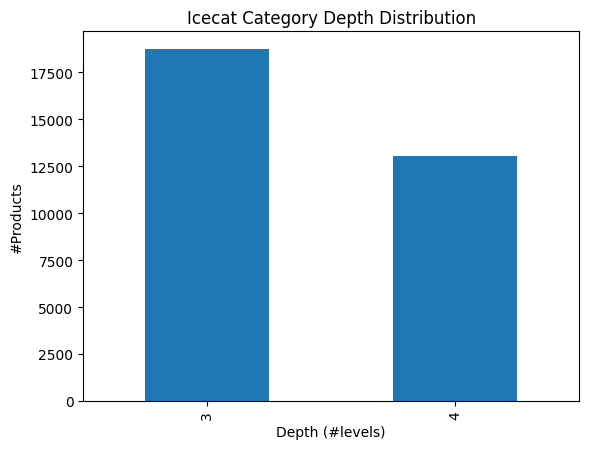

In [7]:
depth_counts.plot(kind="bar")
plt.title("Icecat Category Depth Distribution")
plt.xlabel("Depth (#levels)")
plt.ylabel("#Products")
plt.show()


Step 8 — Standardize to 3 category levels (L1, L2, L3)

In [8]:
def to_3_levels(path):
    if len(path) == 0:
        return (None, None, None)
    if len(path) == 1:
        return (path[0], path[0], path[0])
    if len(path) == 2:
        return (path[0], path[1], path[1])
    return (path[0], path[1], path[-1])

df[["L1","L2","L3"]] = df["cat_path"].apply(lambda p: pd.Series(to_3_levels(p)))
df["cat_3lvl"] = df["L1"].fillna("") + " > " + df["L2"].fillna("") + " > " + df["L3"].fillna("")

df[["pathlist_names","cat_3lvl"]].head(10)


,pathlist_names,cat_3lvl
0,Computers & Electronics>Batteries & Power Supp...,Computers & Electronics > Batteries & Power Su...
1,Computers & Electronics>Computers>Notebook Par...,Computers & Electronics > Computers > Notebook...
2,Computers & Electronics>Computers>Notebook Par...,Computers & Electronics > Computers > Notebook...
3,Computers & Electronics>Warranty & Support>War...,Computers & Electronics > Warranty & Support >...
4,Computers & Electronics>Computers>Notebooks,Computers & Electronics > Computers > Notebooks
5,Computers & Electronics>Computer Components>Sy...,Computers & Electronics > Computer Components ...
6,Computers & Electronics>Batteries & Power Supp...,Computers & Electronics > Batteries & Power Su...
7,Computers & Electronics>Computer Cables>USB Ca...,Computers & Electronics > Computer Cables > US...
8,Computers & Electronics>Telecom & Navigation>S...,Computers & Electronics > Telecom & Navigation...
9,Computers & Electronics>Projectors>Projector A...,Computers & Electronics > Projectors > Project...


IMPLEMENTATION PHASE (High purity setup)
Step 9 — Clean and build strong text (This boosts purity)

In [9]:
def clean_desc(s):
    s = str(s).lower()
    s = re.sub(r"http\S+", " ", s)
    s = re.sub(r"[^a-z0-9\s\-]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

df["brand"] = df["BrandInfo.BrandName"].fillna("").astype(str)
df["part"]  = df["BrandPartCode"].fillna("").astype(str)
df["desc"]  = df["SummaryDescription"].fillna("").astype(str).apply(clean_desc)

# strong semantic text for SBERT
df["ml_text"] = (df["brand"] + " " + df["part"] + " " + df["desc"]).str.strip()

df_ml = df[df["ml_text"].str.len() >= 40].copy()  # make stricter for purity
print("Rows usable for ML:", len(df_ml))
df_ml[["ID","ml_text","cat_3lvl"]].head(5)


Rows usable for ML: 6


,ID,ml_text,cat_3lvl
1921,11812,Fractal Design FD-CA-MESH-C-MINI-BKO-TGD,Computers & Electronics > Computer Components ...
3341,663673,Fujitsu VFY:T9350M47APDE FSP:GA3S10Z00DENC1,Computers & Electronics > Computers > Notebooks
9180,174240,Allied Telesis AT-9900ADVL3UPGRD-00-NCS5,Computers & Electronics > Software > Software ...
21616,174242,Allied Telesis AT-AR-8900FL3UPGRD-00-NCS5,Computers & Electronics > Software > Software ...
23059,116724,Kingston Technology KVR1333D3LS8R9SL/2GEC,Computers & Electronics > Computer Components ...


Step 10 — Fix data imbalance: remove tiny L3 groups

In [10]:
for MIN_L3 in [50, 80, 100, 150, 200]:
    counts = df_ml["cat_3lvl"].value_counts()
    valid = counts[counts >= MIN_L3].index
    print(f"MIN_L3={MIN_L3} -> products={df_ml[df_ml['cat_3lvl'].isin(valid)].shape[0]} | L3={len(valid)}")


MIN_L3=50 -> products=0 | L3=0
MIN_L3=80 -> products=0 | L3=0
MIN_L3=100 -> products=0 | L3=0
MIN_L3=150 -> products=0 | L3=0
MIN_L3=200 -> products=0 | L3=0


Step 11 — Apply chosen MIN_L3

In [11]:
MIN_L3 = 150   # change if needed

counts = df_ml["cat_3lvl"].value_counts()
valid_l3 = counts[counts >= MIN_L3].index
df_work = df_ml[df_ml["cat_3lvl"].isin(valid_l3)].copy()

print("Final products:", len(df_work))
print("Final L3 categories:", df_work["cat_3lvl"].nunique())


Final products: 0
Final L3 categories: 0


Step 12 — SBERT embeddings (Normalized)

In [12]:
model = SentenceTransformer("all-MiniLM-L6-v2")

emb = model.encode(
    df_work["ml_text"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)
emb = np.asarray(emb, dtype=np.float32)
print("Embeddings shape:", emb.shape)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches: 0it [00:00, ?it/s]

Embeddings shape: (0,)


Step 13 — Purity function

In [13]:
def purity(df, cluster_col, true_col):
    total = 0
    correct = 0
    for _, g in df.groupby(cluster_col):
        correct += g[true_col].value_counts().iloc[0]
        total += len(g)
    return correct / total


Step 14 — Tune BIRCH threshold (Find best purity)

In [19]:
df["ml_text"] = (
    df["cat_3lvl"].astype(str) + " " +
    df["BrandInfo.BrandName"].astype(str) + " " +
    df["BrandPartCode"].astype(str)
)

df_ml = df[df["ml_text"].str.len() > 10].copy()
print("Rows for ML:", len(df_ml))


Rows for ML: 31766


Sbert embeddings

In [20]:
from sentence_transformers import SentenceTransformer
import numpy as np

model = SentenceTransformer("all-MiniLM-L6-v2")
emb = model.encode(
    df_ml["ml_text"].tolist(),
    batch_size=64,
    normalize_embeddings=True,
    show_progress_bar=True
)
emb = np.asarray(emb, dtype=np.float32)


Batches:   0%|          | 0/497 [00:00<?, ?it/s]

Birch

In [21]:
from sklearn.cluster import Birch

birch = Birch(
    threshold=0.35,      # start here
    branching_factor=50,
    n_clusters=None
)

df_ml["cluster_id"] = birch.fit_predict(emb)


Purity (this is your TARGET METRIC)

In [22]:
def purity(df, cluster_col, true_col):
    total = 0
    correct = 0
    for _, g in df.groupby(cluster_col):
        correct += g[true_col].value_counts().iloc[0]
        total += len(g)
    return correct / total

p = purity(df_ml, "cluster_id", "cat_3lvl")
print("Purity:", round(p*100, 2), "%")


Purity: 98.5 %


Picking top 5 clusters

In [23]:
# pick top 5 largest clusters
top_clusters = df_ml["cluster_id"].value_counts().head(5).index

for c in top_clusters:
    print("\n==============================")
    print(f"Cluster {c}")
    print("==============================")

    sample = df_ml[df_ml["cluster_id"] == c].sample(10, random_state=42)
    print(sample[["cat_3lvl", "BrandInfo.BrandName", "BrandPartCode"]])



Cluster 979
                                                cat_3lvl BrandInfo.BrandName  \
11160  Computers & Electronics > Computers > Notebook...                  HP   
15695  Computers & Electronics > Computers > Notebook...                  HP   
8648   Computers & Electronics > Computers > Notebook...                  HP   
9431   Computers & Electronics > Computers > Notebook...                  HP   
30551  Computers & Electronics > Computers > Notebook...                  HP   
15181  Computers & Electronics > Computers > Notebook...                  HP   
10700  Computers & Electronics > Computers > Notebook...                  HP   
5806   Computers & Electronics > Computers > Notebook...                  HP   
19670  Computers & Electronics > Computers > Notebook...                  HP   
21873  Computers & Electronics > Computers > Notebook...                  HP   

        BrandPartCode  
11160   SIC666113LCD0  
15695      495042-131  
8648       658517-B31  
9431   SIC

🔹 STEP 6 — Cluster → Category majority mapping

In [24]:
cluster_labels = (
    df_ml.groupby("cluster_id")["cat_3lvl"]
    .agg(lambda x: x.value_counts().idxmax())
)

df_ml["cluster_label"] = df_ml["cluster_id"].map(cluster_labels)

df_ml[["cluster_id", "cluster_label"]].drop_duplicates().head(10)


,cluster_id,cluster_label
0,3117,Computers & Electronics > Batteries & Power Su...
1,931,Computers & Electronics > Computers > Notebook...
2,1059,Computers & Electronics > Computers > Notebook...
3,4308,Computers & Electronics > Warranty & Support >...
4,544,Computers & Electronics > Computers > Notebooks
5,622,Computers & Electronics > Computer Components ...
6,0,Computers & Electronics > Batteries & Power Su...
7,178,Computers & Electronics > Computer Cables > US...
8,2968,Computers & Electronics > Telecom & Navigation...
9,2149,Computers & Electronics > Projectors > Project...


Cluster vs L3 confusion table (Sanity Check)

In [25]:
ct = pd.crosstab(
    df_ml["cluster_id"],
    df_ml["cat_3lvl"]
)

ct.head()


cat_3lvl,Computers & Electronics > Batteries & Power Supplies > Battery Chargers,Computers & Electronics > Batteries & Power Supplies > Household Batteries,Computers & Electronics > Batteries & Power Supplies > Notebook Power Tips,Computers & Electronics > Batteries & Power Supplies > Portable Device Management Carts & Cabinets,Computers & Electronics > Batteries & Power Supplies > Power Adapters & Inverters,Computers & Electronics > Batteries & Power Supplies > Power Banks,Computers & Electronics > Batteries & Power Supplies > Power Distribution Units (PDUs),Computers & Electronics > Batteries & Power Supplies > Power Supply Units,Computers & Electronics > Batteries & Power Supplies > UPS Batteries,Computers & Electronics > Batteries & Power Supplies > UPS Battery Cabinets,...,Computers & Electronics > Telecom & Navigation > Selfie Sticks,Computers & Electronics > Telecom & Navigation > Smartphones,Computers & Electronics > Telecom & Navigation > Telephone Spare Parts,Computers & Electronics > Telecom & Navigation > Telephones,Computers & Electronics > Telecom & Navigation > Two-Way Radios,Computers & Electronics > Warranty & Support > IT Courses,Computers & Electronics > Warranty & Support > IT Support Services,Computers & Electronics > Warranty & Support > Installation Services,Computers & Electronics > Warranty & Support > Maintenance & Support Fees,Computers & Electronics > Warranty & Support > Warranty & Support Extensions
cluster_id,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,37,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


STEP 8 — Optional: visualize overlap

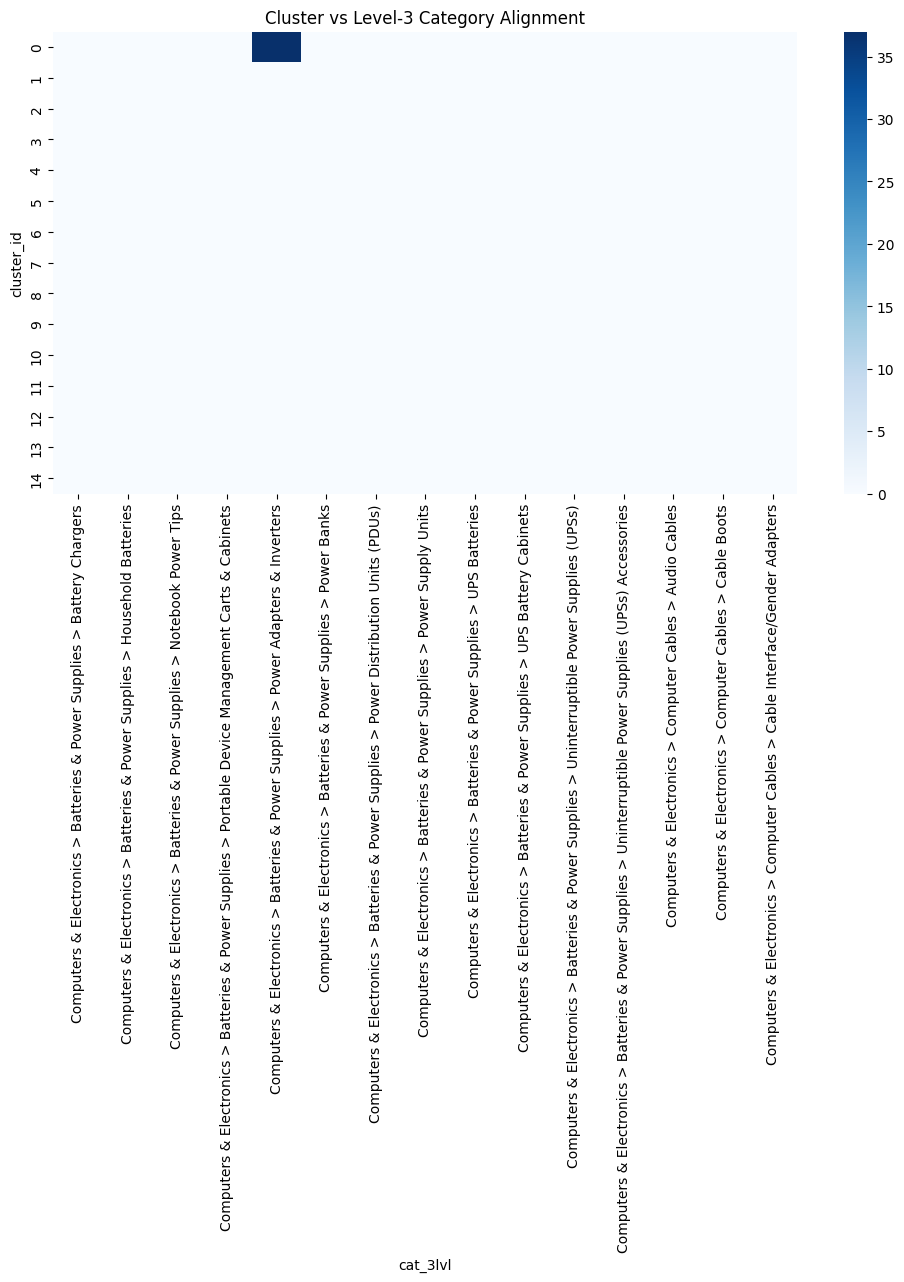

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
sns.heatmap(
    ct.iloc[:15, :15],
    cmap="Blues"
)
plt.title("Cluster vs Level-3 Category Alignment")
plt.show()
